In [1]:
import os

print(os.getcwd())
print(os.listdir())

/home/ec2-user/SageMaker
['start_ollama.sh', '.ipynb_checkpoints', '.sparkmagic', 'ngrok', '01_generador_nombres.ipynb', 'docker-data', 'lost+found', '.virtual_documents', 'Untitled.ipynb']


In [2]:
!find /home/ec2-user/SageMaker -name "dinos.csv"

find: ‘/home/ec2-user/SageMaker/docker-data’: Permission denied
find: ‘/home/ec2-user/SageMaker/lost+found’: Permission denied


In [3]:
import pandas as pd

with open("dinos.txt", "r") as f:
    nombres = [line.strip() for line in f if line.strip()]

df = pd.DataFrame({"name": nombres})
df.to_csv("dinos.csv", index=False)

print(df.head())
print(df.shape)

             name
0   Aachenosaurus
1        Aardonyx
2  Abdallahsaurus
3     Abelisaurus
4   Abrictosaurus
(1536, 1)


In [11]:
import pandas as pd
df = pd.read_csv("dinos.csv")

print(df.head())
print(df.columns)
print(df.shape)

             name
0   Aachenosaurus
1        Aardonyx
2  Abdallahsaurus
3     Abelisaurus
4   Abrictosaurus
Index(['name'], dtype='object')
(1536, 1)


In [12]:
# Normalización
df["name"] = (
    df["name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print(df.head())

             name
0   aachenosaurus
1        aardonyx
2  abdallahsaurus
3     abelisaurus
4   abrictosaurus


In [13]:
PAD = "<PAD>"
BOS = "<BOS>"
EOS = "<EOS>"

In [14]:
PAD = "<PAD>"
BOS = "<BOS>"
EOS = "<EOS>"

caracteres = sorted(set("".join(df["name"].tolist())))

vocab = [PAD, BOS, EOS] + caracteres

char_to_id = {char: i for i, char in enumerate(vocab)}
id_to_char = {i: char for char, i in char_to_id.items()}

print("Caracteres:", caracteres)
print("Tamaño vocabulario:", len(vocab))
print(char_to_id)

Caracteres: ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
Tamaño vocabulario: 29
{'<PAD>': 0, '<BOS>': 1, '<EOS>': 2, 'a': 3, 'b': 4, 'c': 5, 'd': 6, 'e': 7, 'f': 8, 'g': 9, 'h': 10, 'i': 11, 'j': 12, 'k': 13, 'l': 14, 'm': 15, 'n': 16, 'o': 17, 'p': 18, 'q': 19, 'r': 20, 's': 21, 't': 22, 'u': 23, 'v': 24, 'w': 25, 'x': 26, 'y': 27, 'z': 28}


In [15]:
secuencias = []

for nombre in df["name"]:
    secuencia = [BOS] + list(nombre) + [EOS]
    secuencias.append(secuencia)

print(secuencias[:3])

[['<BOS>', 'a', 'a', 'c', 'h', 'e', 'n', 'o', 's', 'a', 'u', 'r', 'u', 's', '<EOS>'], ['<BOS>', 'a', 'a', 'r', 'd', 'o', 'n', 'y', 'x', '<EOS>'], ['<BOS>', 'a', 'b', 'd', 'a', 'l', 'l', 'a', 'h', 's', 'a', 'u', 'r', 'u', 's', '<EOS>']]


In [16]:
max_len = max(len(seq) for seq in secuencias)

print("Longitud máxima:", max_len)

Longitud máxima: 28


In [17]:
secuencias_padded = []

for seq in secuencias:
    padding = [PAD] * (max_len - len(seq))
    secuencias_padded.append(seq + padding)

print(secuencias_padded[0])
print("Longitud:", len(secuencias_padded[0]))

['<BOS>', 'a', 'a', 'c', 'h', 'e', 'n', 'o', 's', 'a', 'u', 'r', 'u', 's', '<EOS>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>']
Longitud: 28


In [18]:
secuencias_ids = []

for seq in secuencias_padded:
    ids = [char_to_id[token] for token in seq]
    secuencias_ids.append(ids)

print(secuencias_ids[0])

[1, 3, 3, 5, 10, 7, 16, 17, 21, 3, 23, 20, 23, 21, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [19]:
import torch

tensor_secuencias = torch.tensor(secuencias_ids, dtype=torch.long)

X = tensor_secuencias[:, :-1]
Y = tensor_secuencias[:, 1:]

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: torch.Size([1536, 27])
Y shape: torch.Size([1536, 27])


In [13]:
print("X:", X[0])
print("Y:", Y[0])

X: tensor([ 1,  3,  3,  5, 10,  7, 16, 17, 21,  3, 23, 20, 23, 21,  2,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0])
Y: tensor([ 3,  3,  5, 10,  7, 16, 17, 21,  3, 23, 20, 23, 21,  2,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0])


In [20]:
from torch.utils.data import TensorDataset, DataLoader, random_split

dataset = TensorDataset(X, Y)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

Train: 1228
Validation: 308


In [15]:
print("Tamaño vocabulario:", len(vocab))
print("Longitud máxima:", max_len)
print("X shape:", X.shape)
print("Y shape:", Y.shape)

Tamaño vocabulario: 29
Longitud máxima: 28
X shape: torch.Size([1536, 27])
Y shape: torch.Size([1536, 27])


In [16]:
import torch.nn as nn

class CharRNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=32, hidden_size=128, num_layers=1):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            emb_dim,
            padding_idx=char_to_id[PAD]
        )

        self.rnn = nn.RNN(
            input_size=emb_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x):
        x = self.embedding(x)
        out, hidden = self.rnn(x)
        logits = self.fc(out)
        return logits

In [21]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", device)

modelo_rnn = CharRNN(
    vocab_size=len(vocab),
    emb_dim=32,
    hidden_size=128,
    num_layers=1
).to(device)

print(modelo_rnn)

Dispositivo: cpu


NameError: name 'CharRNN' is not defined

In [18]:
criterio = nn.CrossEntropyLoss(
    ignore_index=char_to_id[PAD]
)

optimizador = torch.optim.Adam(
    modelo_rnn.parameters(),
    lr=0.001
)

In [23]:
def entrenar_modelo(
    modelo,
    train_loader,
    val_loader,
    criterio,
    optimizador,
    epochs=30
):
    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # ENTRENAMIENTO
        modelo.train()
        train_loss = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizador.zero_grad()

            logits = modelo(xb)

            loss = criterio(
                logits.reshape(-1, logits.size(-1)),
                yb.reshape(-1)
            )

            loss.backward()
            optimizador.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)

        # VALIDACIÓN
        modelo.eval()
        val_loss = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                logits = modelo(xb)

                loss = criterio(
                    logits.reshape(-1, logits.size(-1)),
                    yb.reshape(-1)
                )

                val_loss += loss.item()

        val_loss /= len(val_loader)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

    return train_losses, val_losses

In [20]:
train_rnn, val_rnn = entrenar_modelo(
    modelo_rnn,
    train_loader,
    val_loader,
    criterio,
    optimizador,
    epochs=30
)

Epoch 01/30 | Train: 2.8986 | Val: 2.4636
Epoch 02/30 | Train: 2.3205 | Val: 2.1762
Epoch 03/30 | Train: 2.1251 | Val: 2.0415
Epoch 04/30 | Train: 2.0092 | Val: 1.9478
Epoch 05/30 | Train: 1.9366 | Val: 1.8908
Epoch 06/30 | Train: 1.8901 | Val: 1.8533
Epoch 07/30 | Train: 1.8571 | Val: 1.8193
Epoch 08/30 | Train: 1.8265 | Val: 1.7956
Epoch 09/30 | Train: 1.8051 | Val: 1.7786
Epoch 10/30 | Train: 1.7867 | Val: 1.7503
Epoch 11/30 | Train: 1.7669 | Val: 1.7375
Epoch 12/30 | Train: 1.7392 | Val: 1.7204
Epoch 13/30 | Train: 1.7188 | Val: 1.7068
Epoch 14/30 | Train: 1.7014 | Val: 1.7018
Epoch 15/30 | Train: 1.7099 | Val: 1.6926
Epoch 16/30 | Train: 1.6861 | Val: 1.6730
Epoch 17/30 | Train: 1.6543 | Val: 1.6688
Epoch 18/30 | Train: 1.6538 | Val: 1.6598
Epoch 19/30 | Train: 1.6453 | Val: 1.6577
Epoch 20/30 | Train: 1.6246 | Val: 1.6384
Epoch 21/30 | Train: 1.6324 | Val: 1.6324
Epoch 22/30 | Train: 1.6055 | Val: 1.6301
Epoch 23/30 | Train: 1.6017 | Val: 1.6270
Epoch 24/30 | Train: 1.5926 | Val:

In [29]:
import matplotlib.pyplot as plt

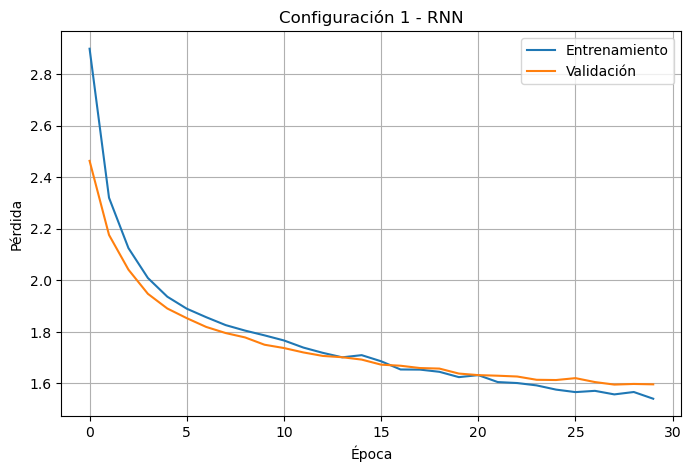

In [23]:
plt.figure(figsize=(8,5))

plt.plot(train_rnn, label="Entrenamiento")
plt.plot(val_rnn, label="Validación")

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Configuración 1 - RNN")

plt.legend()
plt.grid()

plt.show()

In [25]:
import torch
import torch.nn as nn
class CharGRU(nn.Module):
    def __init__(self, vocab_size, emb_dim=64, hidden_size=256, num_layers=2):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            emb_dim,
            padding_idx=char_to_id[PAD]
        )

        self.gru = nn.GRU(
            input_size=emb_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x):
        x = self.embedding(x)
        out, hidden = self.gru(x)
        logits = self.fc(out)
        return logits

In [25]:
modelo_gru = CharGRU(
    vocab_size=len(vocab),
    emb_dim=64,
    hidden_size=256,
    num_layers=2
).to(device)

criterio_gru = nn.CrossEntropyLoss(
    ignore_index=char_to_id[PAD]
)

optimizador_gru = torch.optim.Adam(
    modelo_gru.parameters(),
    lr=0.001
)

print(modelo_gru)

CharGRU(
  (embedding): Embedding(29, 64, padding_idx=0)
  (gru): GRU(64, 256, num_layers=2, batch_first=True)
  (fc): Linear(in_features=256, out_features=29, bias=True)
)


In [26]:
train_gru, val_gru = entrenar_modelo(
    modelo_gru,
    train_loader,
    val_loader,
    criterio_gru,
    optimizador_gru,
    epochs=30
)

Epoch 01/30 | Train: 2.7606 | Val: 2.3243
Epoch 02/30 | Train: 2.1407 | Val: 1.9838
Epoch 03/30 | Train: 1.9216 | Val: 1.8297
Epoch 04/30 | Train: 1.8155 | Val: 1.7566
Epoch 05/30 | Train: 1.7603 | Val: 1.6976
Epoch 06/30 | Train: 1.6972 | Val: 1.6571
Epoch 07/30 | Train: 1.6630 | Val: 1.6212
Epoch 08/30 | Train: 1.6064 | Val: 1.5942
Epoch 09/30 | Train: 1.5601 | Val: 1.5775
Epoch 10/30 | Train: 1.5322 | Val: 1.5569
Epoch 11/30 | Train: 1.5026 | Val: 1.5404
Epoch 12/30 | Train: 1.4649 | Val: 1.5328
Epoch 13/30 | Train: 1.4219 | Val: 1.5255
Epoch 14/30 | Train: 1.3921 | Val: 1.5149
Epoch 15/30 | Train: 1.3543 | Val: 1.5093
Epoch 16/30 | Train: 1.3144 | Val: 1.5098
Epoch 17/30 | Train: 1.2795 | Val: 1.5149
Epoch 18/30 | Train: 1.2380 | Val: 1.5082
Epoch 19/30 | Train: 1.2006 | Val: 1.5204
Epoch 20/30 | Train: 1.1457 | Val: 1.5260
Epoch 21/30 | Train: 1.0993 | Val: 1.5335
Epoch 22/30 | Train: 1.0670 | Val: 1.5465
Epoch 23/30 | Train: 1.0231 | Val: 1.5628
Epoch 24/30 | Train: 0.9848 | Val:

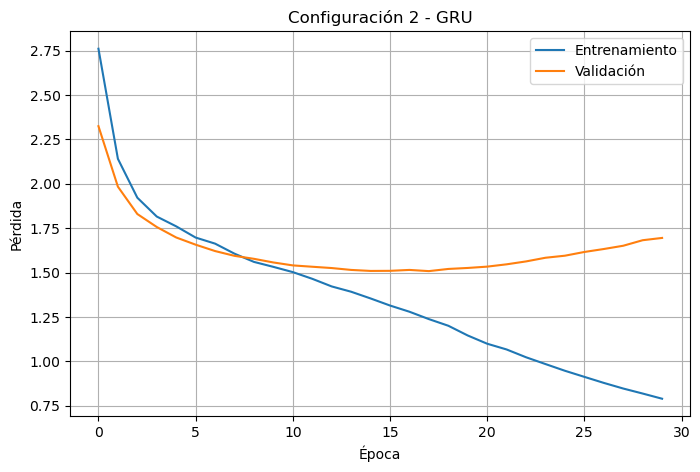

In [27]:
plt.figure(figsize=(8,5))

plt.plot(train_gru, label="Entrenamiento")
plt.plot(val_gru, label="Validación")

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Configuración 2 - GRU")

plt.legend()
plt.grid()

plt.show()

In [26]:
modelo_gru_final = CharGRU(
    vocab_size=len(vocab),
    emb_dim=64,
    hidden_size=256,
    num_layers=2
).to(device)

criterio_gru = nn.CrossEntropyLoss(
    ignore_index=char_to_id[PAD]
)

optimizador_gru_final = torch.optim.Adam(
    modelo_gru_final.parameters(),
    lr=0.001
)

train_gru_final, val_gru_final = entrenar_modelo(
    modelo_gru_final,
    train_loader,
    val_loader,
    criterio_gru,
    optimizador_gru_final,
    epochs=15
)

Epoch 01/15 | Train: 2.7597 | Val: 2.3254
Epoch 02/15 | Train: 2.1756 | Val: 1.9823
Epoch 03/15 | Train: 1.9224 | Val: 1.8291
Epoch 04/15 | Train: 1.8322 | Val: 1.7575
Epoch 05/15 | Train: 1.7581 | Val: 1.7064
Epoch 06/15 | Train: 1.7073 | Val: 1.6646
Epoch 07/15 | Train: 1.6531 | Val: 1.6255
Epoch 08/15 | Train: 1.6227 | Val: 1.5994
Epoch 09/15 | Train: 1.5769 | Val: 1.5799
Epoch 10/15 | Train: 1.5406 | Val: 1.5567
Epoch 11/15 | Train: 1.4989 | Val: 1.5422
Epoch 12/15 | Train: 1.4630 | Val: 1.5369
Epoch 13/15 | Train: 1.4327 | Val: 1.5219
Epoch 14/15 | Train: 1.3922 | Val: 1.5219
Epoch 15/15 | Train: 1.3644 | Val: 1.5151


In [29]:
import torch.nn.functional as F

def sample_next_token(logits, temperature=1.0, top_k=None, top_p=None):
    logits = logits / temperature

    # TOP-K
    if top_k is not None:
        values, indices = torch.topk(logits, top_k)
        probs = F.softmax(values, dim=-1)
        idx = torch.multinomial(probs, 1)
        return indices[idx].item()

    # TOP-P
    if top_p is not None:
        sorted_logits, sorted_indices = torch.sort(logits, descending=True)
        sorted_probs = F.softmax(sorted_logits, dim=-1)
        cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

        mask = cumulative_probs <= top_p
        mask[0] = True

        filtered_probs = sorted_probs[mask]
        filtered_indices = sorted_indices[mask]

        filtered_probs = filtered_probs / filtered_probs.sum()

        idx = torch.multinomial(filtered_probs, 1)
        return filtered_indices[idx].item()

    # Muestreo normal
    probs = F.softmax(logits, dim=-1)
    return torch.multinomial(probs, 1).item()

In [30]:
def generar_nombre(
    modelo,
    temperature=1.0,
    top_k=None,
    top_p=None,
    max_length=30
):
    modelo.eval()

    input_id = torch.tensor(
        [[char_to_id[BOS]]],
        dtype=torch.long
    ).to(device)

    nombre = ""

    with torch.no_grad():
        for _ in range(max_length):

            logits = modelo(input_id)

            next_logits = logits[0, -1]

            next_id = sample_next_token(
                next_logits,
                temperature=temperature,
                top_k=top_k,
                top_p=top_p
            )

            next_char = id_to_char[next_id]

            if next_char == EOS:
                break

            if next_char not in [PAD, BOS]:
                nombre += next_char

            input_id = torch.cat([
                input_id,
                torch.tensor([[next_id]], device=device)
            ], dim=1)

    return nombre

In [31]:
for temp in [0.7, 1.0, 1.3]:
    print(f"\nTemperatura {temp}:")
    
    for _ in range(5):
        print(
            generar_nombre(
                modelo_gru_final,
                temperature=temp
            )
        )


Temperatura 0.7:
apisaurus
sinopelta
achodromimus
icrosaurus
odronykus

Temperatura 1.0:
takacodon
lunskeria
yarnodon
sacriohimus
zhengrosaurus

Temperatura 1.3:
drouqhaeopelcasaurus
sylosaurus
gjiusauris
ngyqanisaurus
enrotitan


In [32]:
print("\nTOP-K:")

for _ in range(5):
    print(
        generar_nombre(
            modelo_gru_final,
            temperature=1.0,
            top_k=5
        )
    )


TOP-K:
toticosaurus
anchisaurus
aleocapteryx
sauropellus
strichosaurus


In [33]:
print("\nTOP-P:")

for _ in range(5):
    print(
        generar_nombre(
            modelo_gru_final,
            temperature=1.0,
            top_p=0.9
        )
    )


TOP-P:
takesaurus
eotrichia
stellamosaurus
palodocephale
beutenosaurus


In [34]:
# Conjunto de nombres reales del dataset
nombres_reales = set(df["name"].str.lower().tolist())

def generar_nombres_unicos(
    modelo,
    cantidad=10,
    temperature=1.0,
    top_k=None,
    top_p=None,
    max_intentos=500
):
    generados = set()
    intentos = 0

    while len(generados) < cantidad and intentos < max_intentos:
        nombre = generar_nombre(
            modelo,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p
        ).lower().strip()

        intentos += 1

        # Filtros básicos
        if len(nombre) < 4:
            continue

        if nombre in nombres_reales:
            continue

        if nombre in generados:
            continue

        generados.add(nombre)

    return sorted(generados)

In [35]:
nombres_finales = generar_nombres_unicos(
    modelo_gru_final,
    cantidad=10,
    temperature=1.0,
    top_p=0.9
)

print("10 nombres nuevos:")
for i, nombre in enumerate(nombres_finales, 1):
    print(f"{i}. {nombre}")

10 nombres nuevos:
1. anopalosaurus
2. ausaurorsoraptor
3. dadosaurus
4. drysaurosaurus
5. lisiachoraptor
6. mamathosaurus
7. manduia
8. rontaceratops
9. sauroratitan
10. shamopala


In [36]:
print("\nVerificación:")
for nombre in nombres_finales:
    print(
        nombre,
        "->",
        "NUEVO" if nombre not in nombres_reales else "YA EXISTE"
    )


Verificación:
anopalosaurus -> NUEVO
ausaurorsoraptor -> NUEVO
dadosaurus -> NUEVO
drysaurosaurus -> NUEVO
lisiachoraptor -> NUEVO
mamathosaurus -> NUEVO
manduia -> NUEVO
rontaceratops -> NUEVO
sauroratitan -> NUEVO
shamopala -> NUEVO


In [37]:
import requests

nombre_dino = "dadosaurus"

url = "http://localhost:11434/api/generate"

prompt = f"""
Inventa un dinosaurio ficticio llamado {nombre_dino}.

Responde en español y usa exactamente estos apartados:

Nombre:
Apariencia:
Hábitat:
Alimentación:
Comportamiento:
Característica distintiva:

Haz la descripción breve, clara y creativa.
"""

data = {
    "model": "llama3.2:3b",
    "prompt": prompt,
    "stream": False
}

response = requests.post(url, json=data)

print("Status:", response.status_code)
print(response.json()["response"])

Status: 200
¡Claro! A continuación, te presento el dinosaurio ficticio llamado Dadosaurus:

**Nombre:** Dadosaurus

El nombre "Dadosaurus" proviene de las palabras latinas "datus", que significa "donado" o "regalo", y "saurus", que significa "serpiente" o "lagarto". Este nombre se refiere a la forma única y serpentiforme que tiene este dinosaurio.

**Apariencia:** El Dadosaurus es un dinosaurio serpentiforme con un cuerpo largo y flexible, similar a una cobra. Su piel es de un color marrón oscuro con patrones de tonos grises y plateados que parecen reflejar la luz. Sus ojos son grandes y redondos, y su cabeza es relativamente pequeña en comparación con su cuerpo. Tiene una cola larga y delgada que utiliza para equilibrarse y evitar obstáculos.

**Hábitat:** El Dadosaurus habita en un ecosistema tropical y húmedo, con árboles altos y densos que cubren la superficie del suelo. Su hábitat se encuentra en regiones con mucha lluvia y humedad, lo que le permite moverse con facilidad y encont

In [38]:
respuesta_dino = response.json()["response"]

print(respuesta_dino)

¡Claro! A continuación, te presento el dinosaurio ficticio llamado Dadosaurus:

**Nombre:** Dadosaurus

El nombre "Dadosaurus" proviene de las palabras latinas "datus", que significa "donado" o "regalo", y "saurus", que significa "serpiente" o "lagarto". Este nombre se refiere a la forma única y serpentiforme que tiene este dinosaurio.

**Apariencia:** El Dadosaurus es un dinosaurio serpentiforme con un cuerpo largo y flexible, similar a una cobra. Su piel es de un color marrón oscuro con patrones de tonos grises y plateados que parecen reflejar la luz. Sus ojos son grandes y redondos, y su cabeza es relativamente pequeña en comparación con su cuerpo. Tiene una cola larga y delgada que utiliza para equilibrarse y evitar obstáculos.

**Hábitat:** El Dadosaurus habita en un ecosistema tropical y húmedo, con árboles altos y densos que cubren la superficie del suelo. Su hábitat se encuentra en regiones con mucha lluvia y humedad, lo que le permite moverse con facilidad y encontrar alimento

In [39]:
nombre_dino = "Dadosaurus"

In [41]:
%pip install -U diffusers transformers accelerate safetensors

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 150.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 83.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 210.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 135.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 159.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.6/797.6 kB 59.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [transformers] [transformers]ub]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import torch
import diffusers
import transformers
import accelerate
import safetensors

print("torch:", torch.__version__)
print("diffusers:", diffusers.__version__)
print("transformers:", transformers.__version__)
print("accelerate:", accelerate.__version__)

torch: 2.10.0+cu128
diffusers: 0.41.0
transformers: 5.20.0
accelerate: 1.15.0


In [2]:
import torch

print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Se usará CPU")

CUDA disponible: False
Se usará CPU


In [3]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:            15Gi       2.6Gi       6.9Gi        90Mi       5.7Gi        12Gi
Swap:             0B          0B          0B


In [4]:
import torch
from diffusers import AutoPipelineForText2Image

modelo_imagen = "stabilityai/sd-turbo"

pipe = AutoPipelineForText2Image.from_pretrained(
    modelo_imagen,
    torch_dtype=torch.float32
)

pipe = pipe.to("cpu")

print("Modelo cargado")

/home/ec2-user/anaconda3/envs/pytorch/lib/python3.10/site-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/home/ec2-user/anaconda3/envs/pytorch/lib/python3.10/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

2026-10-16 07:18:27.555118814 [W:onnxruntime:Default, device_discovery.cc:164 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:89 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Modelo cargado


In [5]:
prompt_imagen = """
A fictional dinosaur called Dadosaurus, full body.
Long flexible serpent-like body similar to a cobra,
dark brown skin with gray and silver reflective patterns,
large round eyes, relatively small head,
long thin tail, tropical humid jungle habitat,
camouflage ability, realistic prehistoric creature,
detailed digital illustration, cinematic lighting.
"""

  0%|          | 0/4 [00:00<?, ?it/s]

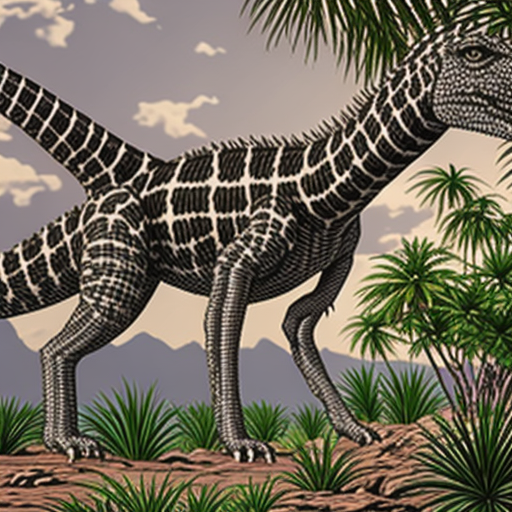

In [6]:
imagen = pipe(
    prompt=prompt_imagen,
    num_inference_steps=4,
    guidance_scale=0.0,
    height=512,
    width=512
).images[0]

display(imagen)

In [7]:
imagen.save("dadosaurus.png")
print("Imagen guardada como dadosaurus.png")

Imagen guardada como dadosaurus.png


In [27]:
import torch
import json

torch.save(
    modelo_gru_final.state_dict(),
    "modelo_gru_dinosaurios.pth"
)

config_modelo = {
    "vocab": vocab,
    "char_to_id": char_to_id,
    "id_to_char": {str(k): v for k, v in id_to_char.items()},
    "embedding_dim": 64,
    "hidden_size": 256,
    "num_layers": 2,
    "modelo": "GRU",
    "epocas": 15,
    "loss": "CrossEntropyLoss ignorando <PAD>",
    "optimizer": "Adam",
    "learning_rate": 0.001
}

with open("config_modelo.json", "w", encoding="utf-8") as f:
    json.dump(config_modelo, f, ensure_ascii=False, indent=2)

print("Modelo y configuración guardados")

Modelo y configuración guardados


In [22]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", device)

Dispositivo: cpu


In [30]:
plt.figure(figsize=(8,5))
plt.plot(train_rnn, label="Entrenamiento")
plt.plot(val_rnn, label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Configuración 1 - RNN")
plt.legend()
plt.grid()
plt.savefig("curva_rnn.png", dpi=150, bbox_inches="tight")
plt.show()

NameError: name 'train_rnn' is not defined

<Figure size 800x500 with 0 Axes>